In [1]:
%pip install -q ultralytics==8.4.174

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 819.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.2 MB/s eta 0:00:00


In [2]:
from pathlib import Path
from google.colab import files
from ultralytics import YOLO
import torch

uploaded = files.upload()

assert "best.pt" in uploaded, "Selecione o arquivo best.pt de detecção."

MODEL_PATH = Path("/content/best.pt")
MODEL_PATH.write_bytes(uploaded["best.pt"])
del uploaded

detector = YOLO(str(MODEL_PATH))

assert detector.task == "detect", (
    "Este modelo não é de detecção. Envie o best.pt do treinamento de folhas."
)
assert list(detector.names.values()) == ["folha"], (
    "O modelo enviado não tem a classe esperada: folha."
)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Detector carregado!")
print("Classes:", detector.names)
print("Dispositivo:", DEVICE)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving best.pt to best.pt
Detector carregado!
Classes: {0: 'folha'}
Dispositivo: cpu


In [3]:
from PIL import Image

uploaded = files.upload()

PHOTO_DIR = Path("/content/fotos_novas")
PHOTO_DIR.mkdir(parents=True, exist_ok=True)

PHOTO_PATHS = []

for name, content in uploaded.items():
    if Path(name).suffix.lower() in [".jpg", ".jpeg", ".png"]:
        path = PHOTO_DIR / Path(name).name
        path.write_bytes(content)

        with Image.open(path) as image:
            image.verify()

        PHOTO_PATHS.append(path)

del uploaded

assert len(PHOTO_PATHS) == 3, (
    f"Foram recebidas {len(PHOTO_PATHS)} imagens. Selecione as três fotos."
)

print("As três fotos foram carregadas:")
for path in PHOTO_PATHS:
    print("-", path.name)

Saving WhatsApp Image 2026-10-11 at 23.32.08 (1).jpeg to WhatsApp Image 2026-10-11 at 23.32.08 (1).jpeg
Saving WhatsApp Image 2026-10-11 at 23.32.08.jpeg to WhatsApp Image 2026-10-11 at 23.32.08.jpeg
Saving WhatsApp Image 2026-10-11 at 23.32.07.jpeg to WhatsApp Image 2026-10-11 at 23.32.07.jpeg
As três fotos foram carregadas:
- WhatsApp Image 2026-10-11 at 23.32.08 (1).jpeg
- WhatsApp Image 2026-10-11 at 23.32.08.jpeg
- WhatsApp Image 2026-10-11 at 23.32.07.jpeg



0: 640x480 1 folha, 256.7ms
1: 640x480 1 folha, 256.7ms
2: 640x480 1 folha, 256.7ms
Speed: 16.4ms preprocess, 256.7ms inference, 15.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/SafraCerta_teste_fotos_reais/previsoes
3 labels saved to /content/SafraCerta_teste_fotos_reais/previsoes/labels

Foto 1: 1 folha(s) detectada(s)
Confiança: 32.3%


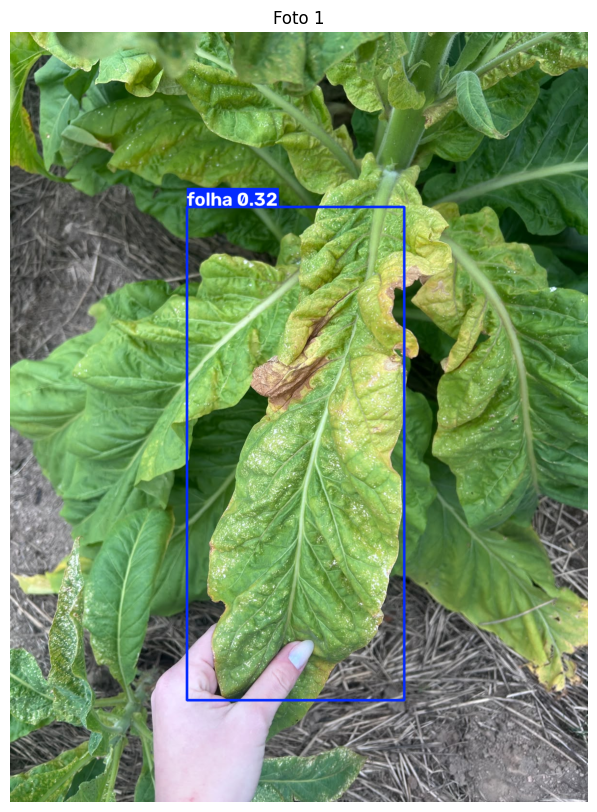


Foto 2: 1 folha(s) detectada(s)
Confiança: 61.1%


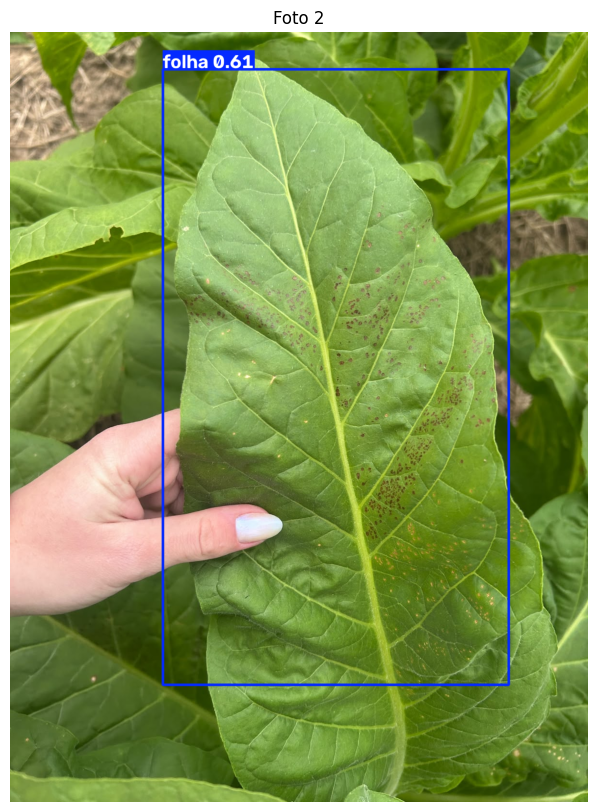


Foto 3: 1 folha(s) detectada(s)
Confiança: 76.4%


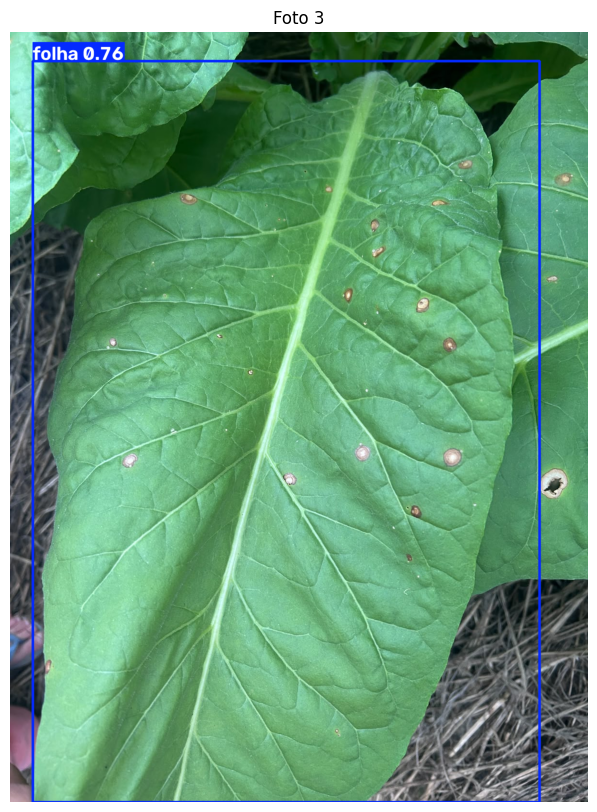

In [4]:
import matplotlib.pyplot as plt

RESULTS_DIR = Path("/content/SafraCerta_teste_fotos_reais")

predictions = detector.predict(
    source=[str(path) for path in PHOTO_PATHS],
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(RESULTS_DIR),
    name="previsoes",
    exist_ok=False
)

for index, result in enumerate(predictions, start=1):
    print(f"\nFoto {index}: {len(result.boxes)} folha(s) detectada(s)")

    for box in result.boxes:
        print(f"Confiança: {float(box.conf.item()):.1%}")

    plt.figure(figsize=(8, 10))
    plt.imshow(result.plot()[..., ::-1])
    plt.title(f"Foto {index}")
    plt.axis("off")
    plt.show()

In [5]:
import json
import shutil
import hashlib

# Pasta da execução que acabou de gerar as previsões
RUN_DIR = Path(predictions[0].save_dir)
ORIGINALS = RUN_DIR / "fotos_originais"
ORIGINALS.mkdir(exist_ok=True)

for path in PHOTO_PATHS:
    shutil.copyfile(path, ORIGINALS / path.name)

summary = {
    "tipo": "Teste qualitativo com três fotos novas de folhas de fumo",
    "modelo_sha256": hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
    "imgsz": 640,
    "confianca_minima": 0.25,
    "observacao": (
        "O detector localizou a folha principal nas três fotos, "
        "mas algumas caixas deixaram partes da folha de fora. "
        "Sem caixas de referência, não foram calculadas métricas. "
        "Não foram testadas imagens sem folhas."
    ),
    "fotos": []
}

for result in predictions:
    summary["fotos"].append({
        "arquivo": Path(result.path).name,
        "deteccoes": [
            {
                "classe": result.names[int(box.cls.item())],
                "confianca": float(box.conf.item()),
                "caixa_xyxy": box.xyxy[0].cpu().tolist()
            }
            for box in result.boxes
        ]
    })

(RUN_DIR / "resumo_teste.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

zip_path = shutil.make_archive(
    "/content/SafraCerta_teste_fotos_reais",
    "zip",
    root_dir=str(RUN_DIR)
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>